In [1]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib as mpl
import pylab as plt
import copy
import os
from scipy.interpolate import interp1d
import pickle
from random import choices, getrandbits
from Grids import *
import BoltzEvolve

In [16]:
T=1           # in K
kT=T*8.62e-5  # in eV
mp=6e9        # in eV

ThermMom=np.sqrt(2*mp*kT) # in eV
ThermVel=ThermMom/mp      # in c

ThermVelNormUnits=ThermVel*3e8 # in ms^-1
#Density=1e18/(215*1e-4)*(0.27/2)        # in m^-3 (lifted from CDR)
Density  = 1e18
CrossSecLi = 3.5e-13    # in m2
CrossSecT = 4.4e-16    # in m2


size=30
grid=Grid2D(size)
mkt=25  #MBDE p^2 for 1 sigma, in grid untis


In [17]:
beLi=BoltzEvolve.Evolver2D(grid,verbose=True,CrossSec=CrossSecLi)
beT=BoltzEvolve.Evolver2D(grid,verbose=True,CrossSec=CrossSecT)



In [20]:
def GetParticleAndEnergyRates(dist,be=beT,Thresh=18,cols=500):
    c2=grid.RR2**2+grid.ZZ2**2

    CutMask=grid.RR2<Thresh
    InvCutMask=np.ones_like(CutMask)-CutMask.astype('int')
    DensityCorrection=sum(sum(dist.f*grid.RR2))/sum(sum(dist.f*CutMask*grid.RR2))
    dist.f=dist.f*CutMask*DensityCorrection
    dfdt=be.GetDfDtFast(dist, cols)

#    print("N")
#    print(sum(sum(dfdt*InvCutMask*grid.RR2)),sum(sum(dist.f*grid.RR2)))
#    print("E")
#    print(sum(sum(c2*dfdt*InvCutMask*grid.RR2)),sum(sum(c2*dist.f*grid.RR2)))
    particlefrac = sum(sum(dfdt*InvCutMask*grid.RR2))/sum(sum(dist.f*grid.RR2))
    energyfrac   = sum(sum(c2*dfdt*InvCutMask*grid.RR2))/sum(sum(c2*dist.f*grid.RR2))
#    plt.imshow(dfdt*grid.RR2,cmap='RdBu')
#    plt.title('dfdt')
#    plt.clim(-6e17,6e17)
#    plt.colorbar()
#    plt.show()
#    plt.imshow(dist.f*grid.RR2)
#    plt.title('dfdt')
#    plt.colorbar()
#    plt.show()
    return particlefrac,energyfrac

In [6]:
allparticlefracs=[]
allenergyfracs=[]
Densities=np.logspace(17,21,5)
#Densities=[Density]
Threshs=np.arange(10,30)

for d in Densities:
    print(d)
    particlefracs=[]
    energyfracs=[]
    for i in Threshs:

        print(i)
        dist=SlicedMB2D(T=T, mkt=mkt, gridpoints=size, m=mp, RCut=50,Rho=d)
        p,e=GetParticleAndEnergyRates(dist,i,1000)
        particlefracs.append(p)
        energyfracs.append(e)
    allparticlefracs.append(particlefracs)
    allenergyfracs.append(energyfracs)

1e+17
10
11


KeyboardInterrupt: 

In [8]:
allparticlefracs=[]
allenergyfracs=[]
Temps=[0.01,0.1,1,10,100]
#Densities=[Density]
Threshs=np.arange(10,30)

for T in Temps:
    print(d)
    particlefracs=[]
    energyfracs=[]
    for i in Threshs:

        print(i)
        dist=SlicedMB2D(T=T, mkt=mkt, gridpoints=size, m=mp, RCut=50,Rho=1e18)
        p,e=GetParticleAndEnergyRates(dist,i,1000)
        particlefracs.append(p)
        energyfracs.append(e)
    allparticlefracs.append(particlefracs)
    allenergyfracs.append(energyfracs)

1e+17
10


KeyboardInterrupt: 

In [ ]:
plt.figure(figsize=(5,5),dpi=200)
Cols=['DarkBlue','DarkRed','purple','black','darkgreen']
for i in range(0,len(allparticlefracs)):

    
    plt.plot((Threshs)**2/(mkt),np.array(allparticlefracs[i])/np.sqrt(Temps[i]),'-',label=r'$T$='+str(Temps[i]) + "K",color=Cols[i])
    plt.plot((Threshs)**2/(mkt),np.array(allenergyfracs[i])/np.sqrt(Temps[i]),'--',color=Cols[i])
plt.xlabel("Cut position units of (mkT)")
plt.ylabel(r"Fractional loss rate/$\sqrt{T}$  [$s^{-1} K^{-1/2}$]")
plt.legend(loc='lower left')
plt.title(r"Tritium, $10^{18}m^{-3}$")
#plt.xlim(1,9)
#plt.ylim(1e-1,1e3)

plt.semilogy()

In [30]:
Threshs=np.arange(10,31)
particlefracsT=[]
energyfracsT=[]
particlefracsLi=[]
energyfracsLi=[]
for i in Threshs:
    print (i)
    dist=SlicedMB2D(T=1, mkt=mkt, gridpoints=size, m=mp, RCut=50,Rho=1e15)
    pT,eT=GetParticleAndEnergyRates(dist,beT,i,1000)
    particlefracsT.append(pT)
    energyfracsT.append(eT)
    pLi,eLi=GetParticleAndEnergyRates(dist,beLi,i,1000)
    particlefracsLi.append(pLi)
    energyfracsLi.append(eLi)

10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30


In [38]:
LogGammaNLi=interp1d((Threshs)**2/(2*mkt),np.log(np.array(particlefracsLi)),bounds_error=False,fill_value='extrapolate')
LogGammaELi=interp1d((Threshs)**2/(2*mkt),np.log(np.array(energyfracsLi)),bounds_error=False,fill_value='extrapolate')
GammaNLi=lambda eta: np.exp(LogGammaNLi(eta))
GammaELi=lambda eta: np.exp(LogGammaELi(eta))

LogGammaNT=interp1d((Threshs)**2/(2*mkt),np.log(np.array(particlefracsT)),bounds_error=False,fill_value='extrapolate')
LogGammaET=interp1d((Threshs)**2/(2*mkt),np.log(np.array(energyfracsT)),bounds_error=False,fill_value='extrapolate')
GammaNT=lambda eta: np.exp(LogGammaNT(eta))
GammaET=lambda eta: np.exp(LogGammaET(eta))

f=open("GammaFile_L1K_rho1e15.pkl",'wb')
pickle.dump([LogGammaE,LogGammaN],f)
f.close()

In [24]:
#f=open("GammaFile_L1K_rho1e18.pkl",'rb')
#LogGammaE,LogGammaN=pickle.load(f)
#f.close()

<>:16: SyntaxWarning: invalid escape sequence '\e'
<>:16: SyntaxWarning: invalid escape sequence '\e'
/var/folders/vy/ll7qjbxx66v846pybl4qyvh80000gs/T/ipykernel_78018/102156143.py:16: SyntaxWarning: invalid escape sequence '\e'
  plt.xlabel("$\eta_{cut}$")


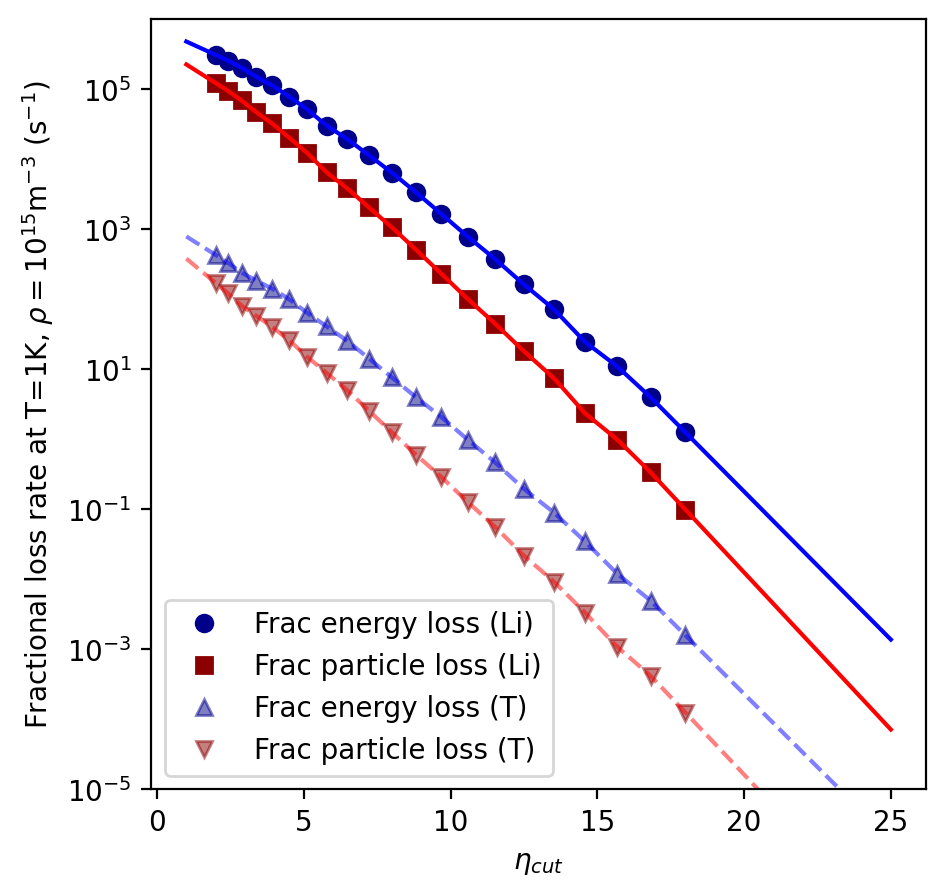

In [37]:
plt.figure(figsize=(5,5),dpi=200)
Cols=['DarkBlue','DarkRed','purple','black','darkgreen']
    
etas=np.linspace(1,25,100)
plt.plot((Threshs)**2/(2*mkt),np.array(energyfracsLi),'o',label=r'Frac energy loss (Li)',color='DarkBlue')
plt.plot((Threshs)**2/(2*mkt),np.array(particlefracsLi),'s',label=r'Frac particle loss (Li)',color='DarkRed')
plt.plot((Threshs)**2/(2*mkt),np.array(energyfracsT),'^',label=r'Frac energy loss (T)',color='DarkBlue',alpha=0.5)
plt.plot((Threshs)**2/(2*mkt),np.array(particlefracsT),'v',label=r'Frac particle loss (T)',color='DarkRed',alpha=0.5)


plt.plot(etas,GammaELi(etas),'-',color='blue')
plt.plot(etas,GammaNLi(etas),'-',color='red')
plt.plot(etas,GammaET(etas),'--',color='blue',alpha=0.5)
plt.plot(etas,GammaNT(etas),'--',color='red',alpha=0.5)

plt.xlabel("$\eta_{cut}$")
plt.ylabel(r"Fractional loss rate at T=1K, $\rho=10^{15}$m$^{-3}$ (s$^{-1}$)")
plt.legend(loc='lower left')
#plt.title("Lithium")
#plt.title(r"Tritium, $10^{18}m^{-3}$")
#plt.xlim(1,9)
#plt.ylim(1e-1,1e3)
plt.ylim(1e-5,1e6)
plt.semilogy()
plt.savefig("GammaPlot.png",dpi=200,bbox_inches='tight')